In [2]:
import os
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyreadstat
from srim import TRIM, Ion, Layer, Target
from srim.output import Results

### Trial


In [3]:
# Stoller et al. (2019) and Barzic et al. (2026)
# 1MeV Cu ions into CuCrZr sample

E0 = 10e6      # incident ion energy, eV
Ed = 25.0     # displacement energy, eV 
density = 8.9

# Incident Fe ion
ion = Ion('Cu', energy=E0)

# CuCrZr Target
layer = Layer({
    'Cu': {
        'stoich': 0.9911,
        'E_d': Ed,
        'lattice': 0.0,     
        'surface': 1e-50
    },
    'Cr': {
        'stoich': 0.0082,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    },
    'Zr': {
        'stoich': 0.0007,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    }
},
density=density,
width=50000.0)

target = Target([layer])

# Quick Kinchin-Pease calculation
trim = TRIM(
    target,
    ion,
    number_ions=100,
    calculation=1 # 1 for Quick KP, 2 for Detailed 
)

srim_directory = r'C:\\Users\\Riz\\Documents\\SRIM'

results = trim.run(srim_directory)

In [8]:
ioniz = results.ioniz
phon = results.phonons
depth = phon.depth

# SRIM divides target into equally spaced depth bins.
dx = np.mean(np.diff(depth))  # Angstrom

# Corrected Stoller damage-energy profile
#
# PHONON columns correspond to the incident-ion and target/recoil
# contributions. The 2019 Stoller erratum requires removal of the
# ion contribution that was double-counted in the original equation.
Tdam_density = phon.recoils - phon.ions   # eV / Angstrom / ion

# Integrate across target thickness
Tdam = np.sum(Tdam_density) * dx          # eV / ion

# NRT displacements per incident ion
N_NRT = 0.8 * Tdam / (2.0 * Ed)

print(f"Damage energy = {Tdam / 1000:.2f} keV/ion")
print(f"NRT displacements = {N_NRT:.1f} displacements/ion")

Damage energy = 495.86 keV/ion
NRT displacements = 7933.8 displacements/ion


In [18]:
phon.recoils

array([100.374  , 123.413  , 109.46   , 131.829  , 133.795  , 131.857  ,
       115.322  ,  82.322  ,  33.593  ,  19.8563 ,  11.9681 ,   2.93849,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,   0.     , 

In [9]:
dx = np.mean(np.diff(ioniz.depth))


Ei_ionization = np.sum(ioniz.ions) * dx
ET_ionization = np.sum(ioniz.recoils) * dx
Ei_phonons = np.sum(phon.ions) * dx

Tdam_balance = (
    E0
    - Ei_ionization
    - ET_ionization
    - Ei_phonons
)

Tdam_phonons = np.sum(
    phon.recoils - phon.ions
) * dx

print()
print("Energy balance check")
print("--------------------")
print(f"Tdam from energy balance = {Tdam_balance / 1000:.3f} keV")
print(f"Tdam from PHONON file    = {Tdam_phonons / 1000:.3f} keV")


Energy balance check
--------------------
Tdam from energy balance = 495.863 keV
Tdam from PHONON file    = 495.862 keV


Atomic density = 8.434e+22 atoms/cm3
Peak NRT dpa   = 2.524


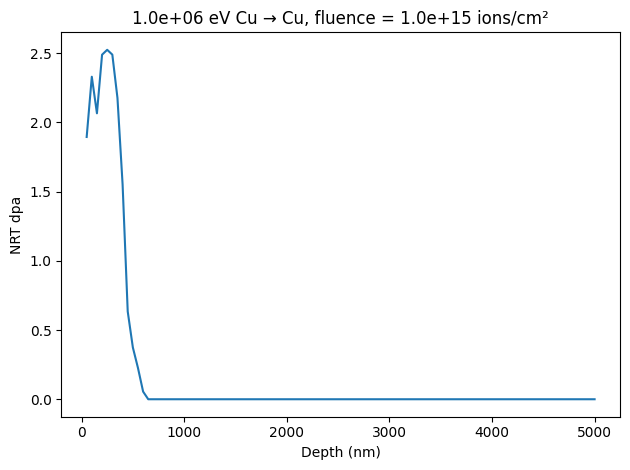

In [19]:
import numpy as np
import matplotlib.pyplot as plt


# Convert damage-energy profile to NRT dpa


fluence = 1.0e15   # ions/cm2

NA = 6.02214076e23     # atoms/mol
M_Cu = 63.546          # g/mol
rho_Cu = 8.9       # g/cm3

# Cu atomic density
atomic_density = rho_Cu * NA / M_Cu   # atoms/cm3

depth_A = phon.depth

# Damage energy per unit depth per incident ion
Tdam_density = phon.recoils - phon.ions
# units: eV / Angstrom / ion

# NRT displacements per Angstrom per incident ion
disp_density = (
    0.8 * Tdam_density
    / (2.0 * Ed)
)
# units: displacements / Angstrom / ion

# Number of target atoms in:
# 1 cm^2 area x 1 Angstrom thickness
atoms_per_A_per_cm2 = atomic_density * 1.0e-8

# dpa at each depth
dpa = (
    disp_density
    * fluence
    / atoms_per_A_per_cm2
)

# Convert depth to nm
depth_nm = depth_A * 0.1

print(f"Atomic density = {atomic_density:.3e} atoms/cm3")
print(f"Peak NRT dpa   = {np.max(dpa):.3f}")

plt.figure()
plt.plot(depth_nm, dpa)
plt.xlabel("Depth (nm)")
plt.ylabel("NRT dpa")
plt.title(f"{E0:.1e} eV Cu → Cu, fluence = {fluence:.1e} ions/cm²")
plt.tight_layout()
plt.show()

### Convergence testing: number of ions
25/09/2026 by Rizqullah Rasyiddin

Re-run TRIM with increasing `number_ions` (same ion/target) to check when
damage-energy and NRT displacement estimates stop changing with more ions.

In [33]:
ion_counts = [100, 500, 1000, 2500,5000,10000]

convergence_records = []
dpa_profiles = {}   # number_ions -> (depth_nm, dpa) for per-run depth profiles

for n in ion_counts:
    trim_conv = TRIM(target, ion, number_ions=n, calculation=1)
    results_conv = trim_conv.run(srim_directory)

    phon_conv = results_conv.phonons
    dx_conv = np.mean(np.diff(phon_conv.depth))

    Tdam_density_conv = phon_conv.recoils - phon_conv.ions
    Tdam_conv = np.sum(Tdam_density_conv) * dx_conv
    N_NRT_conv = 0.8 * Tdam_conv / (2.0 * Ed)

    disp_density_conv = 0.8 * Tdam_density_conv / (2.0 * Ed)
    dpa_conv = disp_density_conv * fluence / atoms_per_A_per_cm2
    peak_dpa_conv = np.max(dpa_conv)

    dpa_profiles[n] = (phon_conv.depth * 0.1, dpa_conv)

    convergence_records.append({
        'number_ions': n,
        'Tdam_keV_per_ion': Tdam_conv / 1000,
        'N_NRT_per_ion': N_NRT_conv,
        'peak_dpa': peak_dpa_conv,
    })

convergence_df = pd.DataFrame(convergence_records)

# Percent change relative to the highest ion count run (proxy for "true" value)
reference = convergence_df.iloc[-1]
convergence_df['N_NRT_pct_diff'] = (
    (convergence_df['N_NRT_per_ion'] - reference['N_NRT_per_ion'])
    / reference['N_NRT_per_ion'] * 100
)
convergence_df['peak_dpa_pct_diff'] = (
    (convergence_df['peak_dpa'] - reference['peak_dpa'])
    / reference['peak_dpa'] * 100
)

convergence_df

,number_ions,Tdam_keV_per_ion,N_NRT_per_ion,peak_dpa,N_NRT_pct_diff,peak_dpa_pct_diff
0,100,489.640027,7834.240434,2.736543,-0.773303,7.019610
1,500,494.188477,7907.015640,2.587049,0.148452,1.173236
2,1000,492.990864,7887.853825,2.558936,-0.094248,0.073824
3,2500,493.237186,7891.794979,2.580636,-0.044330,0.922472
4,5000,492.460613,7879.369806,2.553378,-0.201704,-0.143538
5,10000,493.455934,7895.294949,2.557048,0.000000,0.000000


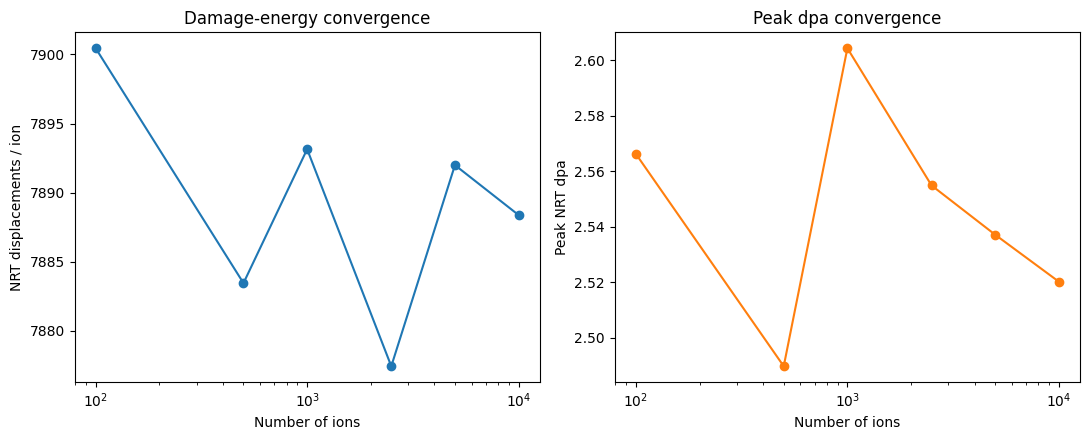

 number_ions  N_NRT_pct_diff  peak_dpa_pct_diff
         100        0.152938           1.824041
         500       -0.062400          -1.207554
        1000        0.060355           3.334383
        2500       -0.138592           1.374905
        5000        0.045800           0.670558
       10000        0.000000           0.000000


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(convergence_df['number_ions'], convergence_df['N_NRT_per_ion'], 'o-')
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of ions')
axes[0].set_ylabel('NRT displacements / ion')
axes[0].set_title('Damage-energy convergence')

axes[1].plot(convergence_df['number_ions'], convergence_df['peak_dpa'], 'o-', color='tab:orange')
axes[1].set_xscale('log')
axes[1].set_xlabel('Number of ions')
axes[1].set_ylabel('Peak NRT dpa')
axes[1].set_title('Peak dpa convergence')

plt.tight_layout()
plt.show()

print(convergence_df[['number_ions', 'N_NRT_pct_diff', 'peak_dpa_pct_diff']].to_string(index=False))

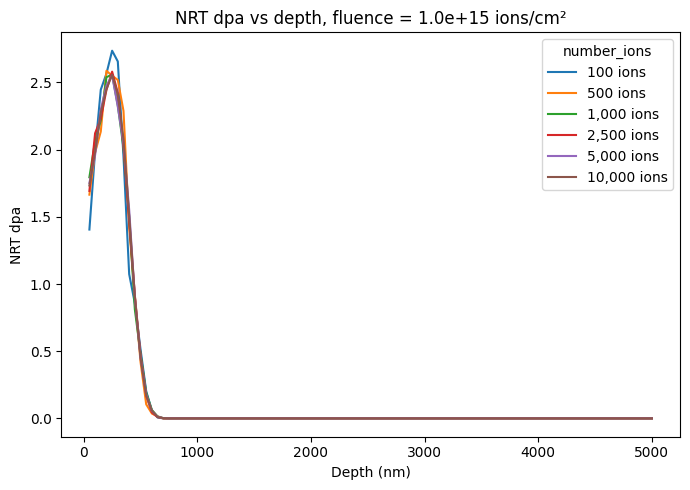

In [34]:
plt.figure(figsize=(7, 5))

for n in ion_counts:
    depth_nm_conv, dpa_conv = dpa_profiles[n]
    plt.plot(depth_nm_conv, dpa_conv, label=f'{n:,} ions')

plt.xlabel('Depth (nm)')
plt.ylabel('NRT dpa')
plt.title(f'NRT dpa vs depth, fluence = {fluence:.1e} ions/cm²')
plt.legend(title='number_ions')
plt.tight_layout()
plt.show()

### Beam Energy and Fluence Study with CuCrZr

28/09/2026 by Rizqullah Rasyiddin

Code to see the effects of changing Incident Beam Energy on CuCrZr with Cu self-ion irradiation. 

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyreadstat
from srim import TRIM, Ion, Layer, Target
from srim.output import Results
import os, pickle

In [16]:
# Stoller et al. (2019) and Barzic et al. (2026)
# Set up layer and target

E0 = 1e6      # incident ion energy, eV
Ed = 25.0     # displacement energy, eV 

# Alloy Composition
at_fraction_Cu = 0.9911
at_fraction_Cr = 0.0082
at_fraction_Zr = 0.0007

# Density Calculation
rho_Cu = 8.96
rho_Cr = 7.19
rho_Zr = 6.52

density = (at_fraction_Cu * rho_Cu + at_fraction_Cr * rho_Cr + at_fraction_Zr * rho_Zr)

# Incident Fe ion
ion = Ion('Cu', energy=E0)

# CuCrZr Target
layer = Layer({
    'Cu': {
        'stoich': at_fraction_Cu,
        'E_d': Ed,
        'lattice': 0.0, # Lattice binding energy zero
        'surface': 1e-50
    },
    'Cr': {
        'stoich': at_fraction_Cr,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    },
    'Zr': {
        'stoich': at_fraction_Zr,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    }
},

density=density,
width=50000.0 # Angstrom
)

target = Target([layer])


srim_directory = r'C:\\Users\\Riz\\Documents\\SRIM'

In [17]:
# fluence is in ions/cm^2, Ed is the displacement energy in eV, atomic_density is in atoms/cm^3

def run_energy_sweep(energies_eV, target, ion_symbol='Cu', number_ions=1000,
                      calculation=1, Ed=25.0, fluence=1.0e15,
                      atomic_density=None, srim_directory=srim_directory):

    # convert atomic density from atoms/cm^3 to atoms/Angstrom/cm^2
    atoms_per_A_per_cm2 = atomic_density * 1.0e-8 

    records = []
    profiles = {}

    for E in energies_eV:
        ion_e = Ion(ion_symbol, energy=E)
        trim_e = TRIM(target, ion_e, number_ions=number_ions, calculation=calculation)
        results_e = trim_e.run(srim_directory)

        phon_e = results_e.phonons
        rng_e = results_e.range
        dx_e = np.mean(np.diff(phon_e.depth))

        Tdam_density_e = phon_e.recoils - phon_e.ions      # eV / Angstrom / ion
        Tdam_e = np.sum(Tdam_density_e) * dx_e             # eV / ion
        N_NRT_e = 0.8 * Tdam_e / (2.0 * Ed)
        disp_density_e = 0.8 * Tdam_density_e / (2.0 * Ed)  # displacements / Angstrom / ion

        record = {
            'energy_eV': E,
            'Tdam_eV_per_ion': Tdam_e,
            'N_NRT_per_ion': N_NRT_e,
        }

        depth_nm_e = phon_e.depth * 0.1 # Convert depth from Angstrom to nm
        profile = {
            'depth_nm': depth_nm_e,
            'Tdam_density': Tdam_density_e,
            'disp_density': disp_density_e,
            'implanted_ions': rng_e.ions
        }

        # dpa calculations
        dpa_e = disp_density_e * fluence / atoms_per_A_per_cm2
        peak_disp_density_e = np.max(disp_density_e)

        record['peak_dpa'] = np.max(dpa_e)
        # fluence (ions/cm2) needed for peak dpa to reach 3.0
        record['fluence_for_3dpa'] = atoms_per_A_per_cm2 / (3 * peak_disp_density_e)

        profile['dpa'] = dpa_e

        profiles[E] = profile
        records.append(record)

    return pd.DataFrame(records), profiles


In [18]:
energy_list = [1e5, 2.5e5, 5e5, 1e6, 2e6, 5e6]  # eV

# Atomic density calculation
fluence = 1.0e15   # ions/cm2

NA = 6.02214076e23     # atoms/mol
M_Cu = 63.546          # g/mol
rho_Cu = 8.9       # g/cm3

atomic_density = rho_Cu * NA / M_Cu   # atoms/cm3

## Run energy sweep simulation, caching results to disk so the sweep doesn't need to be re-run
energy_sweep_cache = os.path.join('srim_outputs', 'energy_sweep_cucrzr.pkl')

if os.path.exists(energy_sweep_cache):
    with open(energy_sweep_cache, 'rb') as f:
        energy_df, energy_profiles = pickle.load(f)
else:
    energy_df, energy_profiles = run_energy_sweep(
        energy_list,
        target,
        ion_symbol='Cu',
        number_ions=1000,
        calculation=1,
        Ed=Ed,
        fluence=fluence,
        atomic_density=atomic_density,
        srim_directory=srim_directory,
    )
    os.makedirs(os.path.dirname(energy_sweep_cache), exist_ok=True)
    with open(energy_sweep_cache, 'wb') as f:
        pickle.dump((energy_df, energy_profiles), f)

energy_df

,energy_eV,Tdam_eV_per_ion,N_NRT_per_ion,peak_dpa,fluence_for_3dpa
0,100000.0,7.020304e+04,1123.248705,2.574063,1.294970e+14
1,250000.0,1.621693e+05,2594.709565,3.315181,1.005475e+14
2,500000.0,2.934850e+05,4695.760657,3.026864,1.101250e+14
3,1000000.0,4.919283e+05,7870.852654,2.500674,1.332974e+14
4,2000000.0,7.397342e+05,11835.747482,2.253346,1.479282e+14
5,5000000.0,1.071435e+06,17142.960614,1.974338,1.688330e+14


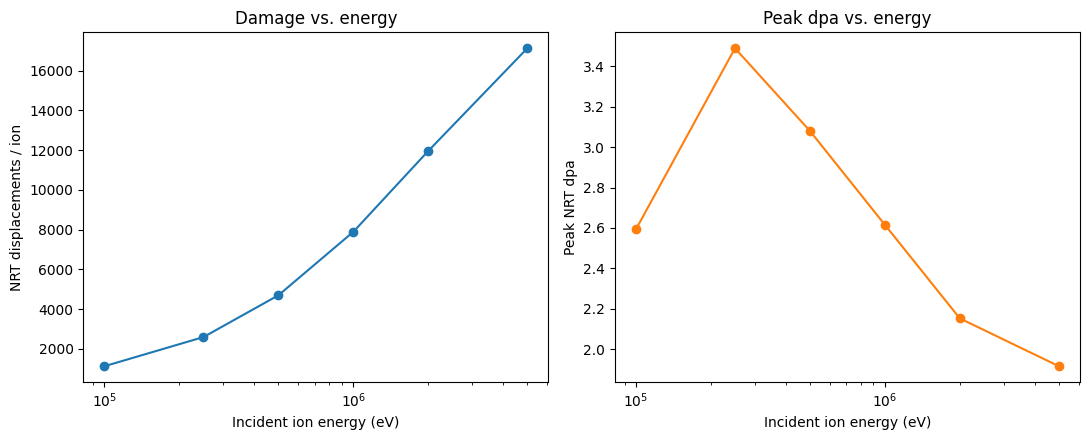

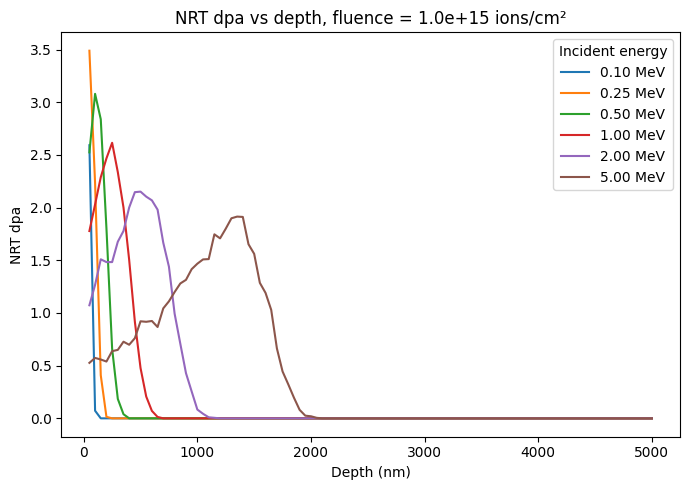

 energy_eV  peak_dpa  fluence_for_3dpa
  100000.0  2.592636      1.285693e+14
  250000.0  3.489855      9.551494e+13
  500000.0  3.080317      1.082140e+14
 1000000.0  2.615682      1.274365e+14
 2000000.0  2.152174      1.548821e+14
 5000000.0  1.915123      1.740532e+14


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(energy_df['energy_eV'], energy_df['N_NRT_per_ion'], 'o-')
axes[0].set_xscale('log')
axes[0].set_xlabel('Incident ion energy (eV)')
axes[0].set_ylabel('NRT displacements / ion')
axes[0].set_title('Damage vs. energy')

axes[1].plot(energy_df['energy_eV'], energy_df['peak_dpa'], 'o-', color='tab:orange')
axes[1].set_xscale('log')
axes[1].set_xlabel('Incident ion energy (eV)')
axes[1].set_ylabel('Peak NRT dpa')
axes[1].set_title('Peak dpa vs. energy')

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
for E in energy_list:
    profile = energy_profiles[E]
    plt.plot(profile['depth_nm'], profile['dpa'], label=f'{E / 1e6:.2f} MeV')

plt.xlabel('Depth (nm)')
plt.ylabel('NRT dpa')
plt.title(f'NRT dpa vs depth, fluence = {fluence:.1e} ions/cm²')
plt.legend(title='Incident energy')
plt.tight_layout()
plt.show()

print(energy_df[['energy_eV', 'peak_dpa', 'fluence_for_3dpa']].to_string(index=False))


In [2]:
fluence_list = [5e14, 1e15, 2.5e15, 3e15]
E = 5e6 # Choose 5MeV for example
threshold = 3 # 3 dpa
atoms_per_A_per_cm2 = atomic_density * 1.0e-8 
for fluence in fluence_list:
    profile = energy_profiles[E]
    dpa_profile = profile['disp_density'] * fluence / atoms_per_A_per_cm2
    dx_nm = np.mean(np.diff(profile['depth_nm']))

    plt.plot(profile['depth_nm'], dpa_profile, label=f'{fluence:.1e} ions/cm²')

plt.xlabel('Depth (nm)')
plt.ylabel('NRT dpa')
plt.xlim(0,2500)
plt.title(f'NRT dpa vs depth, Incident Energy = {E:.1e} eV')
plt.axhline(y=threshold, color='k', linestyle='--', label=f'Min Bound: {threshold} dpa')
plt.axvline(x=550, color='g', linestyle='--')
plt.axvline(x=1050, color='g', linestyle='--')
# plt.axvline(x=400, color='r', linestyle='--')
# plt.axvline(x=850, color='r', linestyle='--')
plt.legend(title='Fluence')
plt.tight_layout()
plt.show()


NameError: name 'atomic_density' is not defined

In [10]:
target_mean_dpa = 3.0
tol = 0.05  # acceptable deviation from target mean dpa
min_depth_nm = 200.0  # exclude near-surface region prone to surface effects
max_width_nm = 500.0  # cap on how large the ROI is allowed to be

for fluence in fluence_list:
    profile = energy_profiles[E]
    dpa_profile = profile['disp_density'] * fluence / atoms_per_A_per_cm2
    depth_nm = profile['depth_nm']
    peak_idx = np.argmax(dpa_profile)

    # cumulative trapezoidal integral of dpa over depth, for O(1) window-mean lookups
    trapz_areas = (dpa_profile[:-1] + dpa_profile[1:]) / 2 * np.diff(depth_nm)
    cum_dpa = np.concatenate(([0.0], np.cumsum(trapz_areas)))

    best_width = 0.0
    best_window = None
    n = len(depth_nm)

    for i in range(n - 1):
        if depth_nm[i] < min_depth_nm:
            continue  # skip near-surface region

        j_indices = np.arange(i + 1, n)
        widths = depth_nm[j_indices] - depth_nm[i]
        means = (cum_dpa[j_indices] - cum_dpa[i]) / widths

        # window must stay entirely before or entirely after the peak, not straddle it
        side_ok = (j_indices <= peak_idx) | (i >= peak_idx)

        valid = (np.abs(means - target_mean_dpa) <= tol) & side_ok & (widths <= max_width_nm)
        if valid.any():
            rel = np.argmax(np.where(valid, widths, -1))
            width = widths[rel]
            if width > best_width:
                best_width = width
                best_window = (depth_nm[i], depth_nm[j_indices[rel]], means[rel])

    if best_window:
        d1, d2, mean_dpa = best_window
        print(f"Fluence {fluence:.1e}: widest region with mean dpa ~ {target_mean_dpa} is "
              f"{d1:.1f}-{d2:.1f} nm ({best_width:.1f} nm wide, mean = {mean_dpa:.3f} dpa)")
    else:
        print(f"Fluence {fluence:.1e}: no region found with mean dpa within {tol} of {target_mean_dpa}")


Fluence 5.0e+14: no region found with mean dpa within 0.05 of 3.0
Fluence 1.0e+15: no region found with mean dpa within 0.05 of 3.0
Fluence 2.5e+15: widest region with mean dpa ~ 3.0 is 550.0-1050.0 nm (500.0 nm wide, mean = 2.959 dpa)
Fluence 3.0e+15: widest region with mean dpa ~ 3.0 is 450.0-850.0 nm (400.0 nm wide, mean = 3.001 dpa)


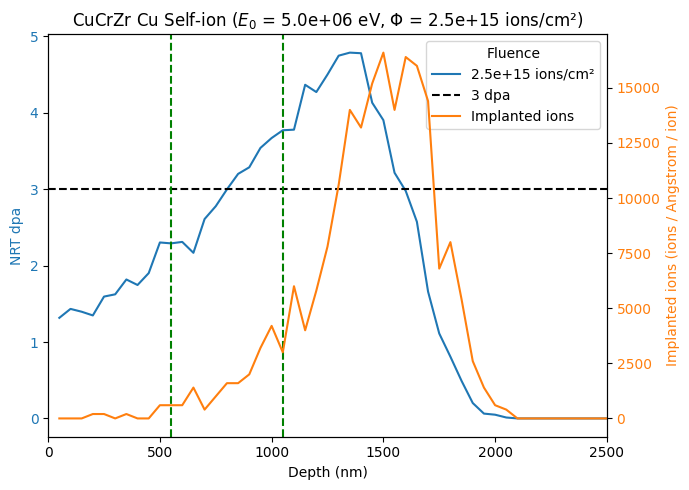

In [18]:
fluence = 2.5e15
profile = energy_profiles[5e6]
dpa_profile = profile['disp_density'] * fluence / atoms_per_A_per_cm2

fig, ax1 = plt.subplots(figsize=(7, 5))
ax2 = ax1.twinx()  # secondary y-axis sharing the same x-axis

ax1.plot(profile['depth_nm'], dpa_profile, color='tab:blue', label=f'{fluence:.1e} ions/cm²')
ax2.plot(profile['depth_nm'], profile['implanted_ions'], color='tab:orange', label='Implanted ions')

ax1.axhline(y=threshold, color='k', linestyle='--', label=f'{threshold} dpa')
ax1.axvline(x=550, color='g', linestyle='--')
ax1.axvline(x=1050, color='g', linestyle='--')

ax1.set_xlim(0, 2500)
ax1.set_xlabel('Depth (nm)')
ax1.set_ylabel('NRT dpa', color='tab:blue')
ax2.set_ylabel('Implanted ions (ions / Angstrom / ion)', color='tab:orange')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:orange')

ax1.set_title(rf'CuCrZr Cu Self-ion ($E_0$ = {E:.1e} eV, $\Phi$ = {fluence:.1e} ions/cm²)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, title='Fluence')

plt.tight_layout()
plt.show()

### CuCrTa Comparison 

28/09/2026 by Rizqullah Rasyiddin

Comparison of dpa profile and implanted ions profile with CuCrZr. Same fluence of 2.5e15 ions/cm2 and E0 of 5MeV Cu self-ion

In [19]:
# Stoller et al. (2019) and Barzic et al. (2026)
# Set up layer and target

E0 = 5e6      # incident ion energy, eV
Ed = 25.0     # displacement energy, eV 

# Alloy Composition
at_fraction_Cr = 0.8/100
at_fraction_Ta = 0.4/100
at_fraction_Cu = 1 - at_fraction_Cr - at_fraction_Ta

# Density Calculation
rho_Cu = 8.96
rho_Cr = 7.19
rho_Ta = 16.69

density = (at_fraction_Cu * rho_Cu + at_fraction_Cr * rho_Cr + at_fraction_Ta * rho_Ta)

# Incident Fe ion
ion = Ion('Cu', energy=E0)

# CuCrZr Target
layer = Layer({
    'Cu': {
        'stoich': at_fraction_Cu,
        'E_d': Ed,
        'lattice': 0.0, # Lattice binding energy zero
        'surface': 1e-50
    },
    'Cr': {
        'stoich': at_fraction_Cr,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    },
    'Ta': {
        'stoich': at_fraction_Ta,
        'E_d': Ed,
        'lattice': 1e-50,
        'surface': 1e-50
    }
},

density=density,
width=50000.0 # Angstrom
)

target = Target([layer])


srim_directory = r'C:\\Users\\Riz\\Documents\\SRIM'

# Quick Kinchin-Pease calculation
trim = TRIM(
    target,
    ion,
    number_ions=1000,
    calculation=1 # 1 for Quick KP, 2 for Detailed 
)

results_cucrta = trim.run(srim_directory)

In [47]:
# fluence is in ions/cm^2, Ed is the displacement energy in eV, atomic_density is in atoms/cm^3

def run_composition_sweep(Cr_frac_list, E0, number_ions=1000,
                      calculation=1, Ed=25.0, fluence=1.0e15, srim_directory=srim_directory):

    NA = 6.02214076e23     # atoms/mol
    M_Cu = 63.546          # g/mol
    M_Cr = 51.9961         
    M_Ta = 180.94788       
    rho_Cu = 8.96
    rho_Cr = 7.19
    rho_Ta = 16.69         # g/cm3

    atomic_density = rho_Cu * NA / M_Cu   # atoms/cm3
    atoms_per_A_per_cm2 = atomic_density * 1.0e-8 

    records = []
    profiles = {}

    for Cr_frac in Cr_frac_list:
        # Alloy Composition
        at_fraction_Cr = Cr_frac/100
        at_fraction_Ta = Cr_frac/200
        at_fraction_Cu = 1 - at_fraction_Cr - at_fraction_Ta

        # Density Calculation

        weight_density = (at_fraction_Cu * rho_Cu + at_fraction_Cr * rho_Cr + at_fraction_Ta * rho_Ta)  # g/cm3


        atomic_density = weight_density * NA / (at_fraction_Cu * M_Cu + at_fraction_Cr * M_Cr + at_fraction_Ta * M_Ta)   # atoms/cm3
        # convert atomic density from atoms/cm^3 to atoms/Angstrom/cm^2    
        atoms_per_A_per_cm2 = atomic_density * 1.0e-8 

        # Incident Cu ion
        ion = Ion('Cu', energy=E0)

        # CuCrZr Target
        layer = Layer({
            'Cu': {
                'stoich': at_fraction_Cu,
                'E_d': Ed,
                'lattice': 0.0, # Lattice binding energy zero
                'surface': 1e-50
            },
            'Cr': {
                'stoich': at_fraction_Cr,
                'E_d': Ed,
                'lattice': 1e-50,
                'surface': 1e-50
            },
            'Ta': {
                'stoich': at_fraction_Ta,
                'E_d': 32,
                'lattice': 1e-50,
                'surface': 1e-50
            }
        },

        density=weight_density,
        width=50000.0 # Angstrom
        )

        # Initialise target
        target = Target([layer])

        # Incident Cu ion for the simulation
        ion_e = Ion('Cu', energy=E)

        # Run the TRIM simulation
        trim_e = TRIM(target, ion_e, number_ions=number_ions, calculation=calculation)
        results_e = trim_e.run(srim_directory)

        # Extract phonon and range results from the simulation
        phon_e = results_e.phonons
        rng_e = results_e.range

        # Calculate the SRIM bin depth
        dx_e = np.mean(np.diff(phon_e.depth))

        # Calculate the damage energy density and total damage energy
        Tdam_density_e = phon_e.recoils - phon_e.ions      # eV / Angstrom / ion
        Tdam_e = np.sum(Tdam_density_e) * dx_e             # eV / ion
        N_NRT_e = 0.8 * Tdam_e / (2.0 * Ed) # NRT displacements
        disp_density_e = 0.8 * Tdam_density_e / (2.0 * Ed)  # displacements / Angstrom / ion

        # Store scalar results in a record dictionary
        record = {
            'Cr_comp_atperc': Cr_frac,
            'Ta_comp_atperc': Cr_frac/2,
            'Tdam_eV_per_ion': Tdam_e,
            'N_NRT_per_ion': N_NRT_e,
        }

        depth_nm_e = phon_e.depth * 0.1 # Convert depth from Angstrom to nm

        # Store depth and damage profiles in a profile dictionary
        profile = {
            'depth_nm': depth_nm_e,
            'Tdam_density': Tdam_density_e,
            'disp_density': disp_density_e,
            'implanted_ions': rng_e.ions
        }

        # dpa calculations
        dpa_e = disp_density_e * fluence / atoms_per_A_per_cm2
        peak_disp_density_e = np.max(disp_density_e)

        record['peak_dpa'] = np.max(dpa_e)

        # fluence (ions/cm2) needed for peak dpa to reach 3.0
        record['fluence_for_3dpa'] = (3*atoms_per_A_per_cm2) / (peak_disp_density_e)

        profile['dpa'] = dpa_e

        profiles[Cr_frac] = profile
        records.append(record)

    return pd.DataFrame(records), profiles


In [48]:
Cr_comp_list = [0.8,1.2,2.0]

# Initialise beam parameters from earlier fluence and beam energy study for CuCrZr
E0 = 5e6 # eV
fluence = 2.5e15   # ions/cm2

## Run comp sweep simulation, caching results to disk so the sweep doesn't need to be re-run
composition_sweep_cache = os.path.join('srim_outputs', 'composition_sweep_cucrta.pkl')

if os.path.exists(composition_sweep_cache):
    with open(composition_sweep_cache, 'rb') as f:
        composition_df, composition_profiles = pickle.load(f)
else:
    composition_df, composition_profiles = run_composition_sweep(
        Cr_comp_list,
        E0,
        number_ions=1000,
        calculation=1,
        Ed=25,
        fluence=fluence,
        srim_directory=srim_directory
    )
    os.makedirs(os.path.dirname(composition_sweep_cache), exist_ok=True)
    with open(composition_sweep_cache, 'wb') as f:
        pickle.dump((composition_df, composition_profiles), f)

composition_df

,Cr_comp_atperc,Ta_comp_atperc,Tdam_eV_per_ion,N_NRT_per_ion,peak_dpa,fluence_for_3dpa
0,0.8,0.4,1.070571e+06,17129.137767,4.660885,1.609136e+15
1,1.2,0.6,1.076891e+06,17230.263003,4.861963,1.542587e+15
2,2.0,1.0,1.078343e+06,17253.485218,4.826689,1.553860e+15


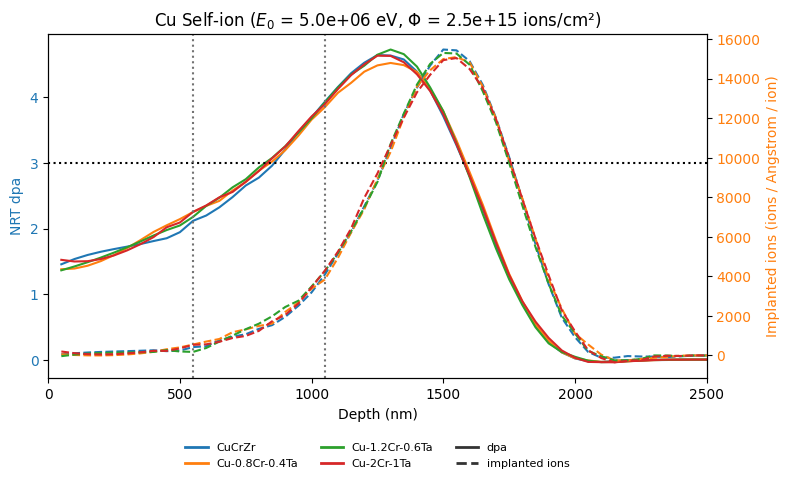

In [ ]:
# Chosen fluence in ions/cm²
fluence = 2.5e15

from scipy.signal import savgol_filter
from matplotlib.lines import Line2D

# Savitzky-Golay smoothing to reduce SRIM Monte-Carlo bin noise while preserving peak shape
def smooth(y, window=15, poly=3):
    window = min(window, len(y) - (1 - len(y) % 2))  
    return savgol_filter(y, window, poly) if window > poly else y

fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()

# Atomic Density
NA = 6.02214076e23     # atoms/mol
M_Cu = 63.546          # g/mol
M_Cr = 51.9961
M_Ta = 180.94788
rho_Cu = 8.96
rho_Cr = 7.19
rho_Ta = 16.69         # g/cm3

atomic_density = rho_Cu * NA / M_Cu   # atoms/cm3
atoms_per_A_per_cm2 = atomic_density * 1.0e-8

colors = ['tab:orange', 'tab:green', 'tab:red']

# Solid lines show dpa; dashed lines show implanted ions for the same material.
cucrzr_profile = energy_profiles[5e6]
cucrzr_dpa_profile = cucrzr_profile['disp_density'] * fluence / atoms_per_A_per_cm2
ax1.plot(
    cucrzr_profile['depth_nm'],
    smooth(cucrzr_dpa_profile),
    color='tab:blue',
    linestyle='-',
)
ax2.plot(
    cucrzr_profile['depth_nm'],
    smooth(cucrzr_profile['implanted_ions']),
    color='tab:blue',
    linestyle='--',
)

for Cr_frac, color in zip(Cr_comp_list, colors):
    composition_label = f'Cu-{Cr_frac:g}Cr-{Cr_frac / 2:g}Ta'
    weight_density = (
        at_fraction_Cu * rho_Cu
        + at_fraction_Cr * rho_Cr
        + at_fraction_Ta * rho_Ta
    )
    atomic_density = weight_density * NA / (
        at_fraction_Cu * M_Cu
        + at_fraction_Cr * M_Cr
        + at_fraction_Ta * M_Ta
    )
    atoms_per_A_per_cm2 = atomic_density * 1.0e-8
    cucrta_profile = composition_profiles[Cr_frac]
    dpa_profile = cucrta_profile['disp_density'] * fluence / atoms_per_A_per_cm2

    ax1.plot(
        cucrta_profile['depth_nm'],
        smooth(dpa_profile),
        color=color,
        linestyle='-',
    )
    ax2.plot(
        cucrta_profile['depth_nm'],
        smooth(cucrta_profile['implanted_ions']),
        color=color,
        linestyle='--',
    )

ax1.axhline(y=threshold, color='k', linestyle=':', label=f'{threshold} dpa threshold')
ax1.axvline(x=550, color='0.45', linestyle=':', label='ROI boundary')
ax1.axvline(x=1050, color='0.45', linestyle=':')

ax1.set_xlim(0, 2500)
ax1.set_xlabel('Depth (nm)')
ax1.set_ylabel('NRT dpa', color='tab:blue')
ax2.set_ylabel('Implanted ions (ions / Angstrom / ion)', color='tab:orange')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:orange')

ax1.set_title(rf'Cu Self-ion ($E_0$ = {E:.1e} eV, $\Phi$ = {fluence:.1e} ions/cm²)')

material_handles = [
    Line2D([0], [0], color='tab:blue', lw=2, label='CuCrZr'),
    Line2D([0], [0], color='tab:orange', lw=2, label='Cu-0.8Cr-0.4Ta'),
    Line2D([0], [0], color='tab:green', lw=2, label='Cu-1.2Cr-0.6Ta'),
    Line2D([0], [0], color='tab:red', lw=2, label='Cu-2Cr-1Ta'),
]
quantity_handles = [
    Line2D([0], [0], color='0.2', lw=2, linestyle='-', label='dpa'),
    Line2D([0], [0], color='0.2', lw=2, linestyle='--', label='implanted ions'),
]
ax1.legend(
    handles=material_handles + quantity_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    fontsize=8,
    frameon=False,
)

plt.tight_layout()
plt.show()